# Data Scientist Professional Practical Exam Submission

**Use this template to write up your summary for submission. Code in Python or R needs to be included.**


## 📝 Task List

Your written report should include both code, output and written text summaries of the following:
- Data Validation:   
  - Describe validation and cleaning steps for every column in the data 
- Exploratory Analysis:  
  - Include two different graphics showing single variables only to demonstrate the characteristics of data  
  - Include at least one graphic showing two or more variables to represent the relationship between features
  - Describe your findings
- Model Development
  - Include your reasons for selecting the models you use as well as a statement of the problem type
  - Code to fit the baseline and comparison models
- Model Evaluation
  - Describe the performance of the two models based on an appropriate metric
- Business Metrics
  - Define a way to compare your model performance to the business
  - Describe how your models perform using this approach
- Final summary including recommendations that the business should undertake

*Start writing report here..*

In [4]:
# Start coding here...

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("data/recipe_site_traffic.csv")

# Display initial information
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (947, 8)


,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,NaN,NaN,NaN,NaN,Pork,6,High
1,2,35.48,38.56,0.66,0.92,Potato,4,High
2,3,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,4,97.03,30.56,38.63,0.02,Beverages,4,High
4,5,27.05,1.85,0.80,0.53,Beverages,4,NaN


Cleaned dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   recipe        947 non-null    int64  
 1   calories      895 non-null    float64
 2   carbohydrate  895 non-null    float64
 3   sugar         895 non-null    float64
 4   protein       895 non-null    float64
 5   category      947 non-null    object 
 6   servings      947 non-null    int64  
 7   high_traffic  947 non-null    string 
dtypes: float64(4), int64(2), object(1), string(1)
memory usage: 59.3+ KB

Missing values after cleaning:
recipe           0
calories        52
carbohydrate    52
sugar           52
protein         52
category         0
servings         0
high_traffic     0
dtype: int64

Category values:
Chicken          172
Breakfast        106
Beverages         92
Lunch/Snacks      89
Potato            88
Pork              84
Vegetable         83
D

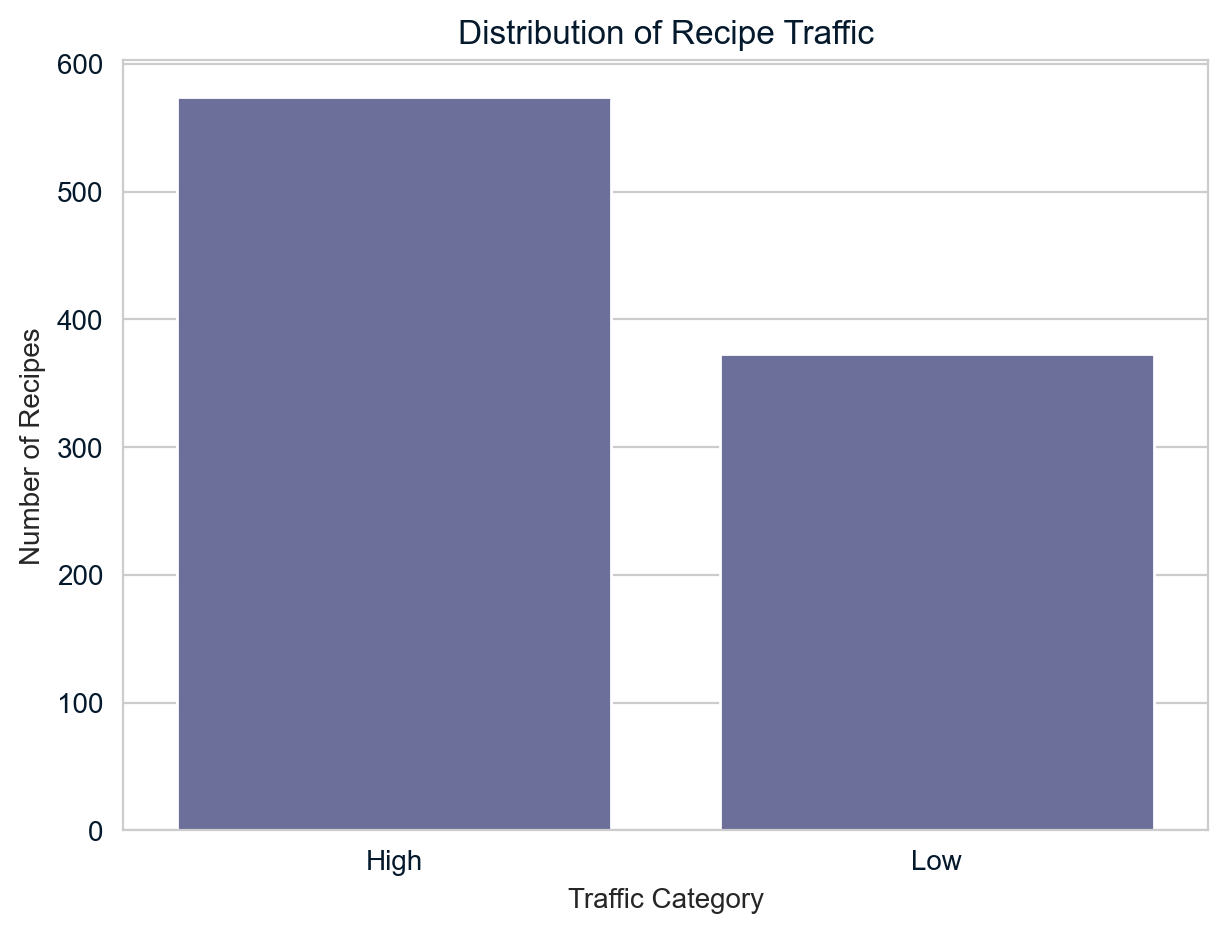

In [5]:
# Initial inspection

# print("Dataset information:")
# df.info()

# print("\nMissing values:")
# print(df.isnull().sum())

# print("\nDuplicate rows:", df.duplicated().sum())

# print("\nUnique values in each column:")
# for col in df.columns:
#     print(f"\n{col}:")
#     print(df[col].value_counts(dropna=False).head(15))

# Create a copy of the original dataset
df_clean = df.copy()

# Convert nutritional columns to numeric
numeric_cols = ['calories', 'carbohydrate', 'sugar', 'protein']

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Standardize category names
df_clean['category'] = df_clean['category'].str.strip().str.title()

# Combine Chicken Breast and Chicken
df_clean['category'] = df_clean['category'].replace({
    'Chicken Breast': 'Chicken'
})

# Extract numeric serving values
df_clean['servings'] = (
    df_clean['servings']
    .astype(str)
    .str.extract(r'(\d+)')[0]
)

df_clean['servings'] = pd.to_numeric(
    df_clean['servings'], errors='coerce'
)

# Standardize target column
df_clean['high_traffic'] = (
    df_clean['high_traffic']
    .astype('string')
    .str.strip()
    .str.title()
)

# Treat missing target values as Low
df_clean['high_traffic'] = df_clean['high_traffic'].fillna('Low')

# Display cleaned dataset information
print("Cleaned dataset information:")
df_clean.info()

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCategory values:")
print(df_clean['category'].value_counts())

print("\nServing values:")
print(df_clean['servings'].value_counts())

print("\nTarget distribution:")
print(df_clean['high_traffic'].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x='high_traffic'
)

plt.title('Distribution of Recipe Traffic')
plt.xlabel('Traffic Category')
plt.ylabel('Number of Recipes')

plt.show()


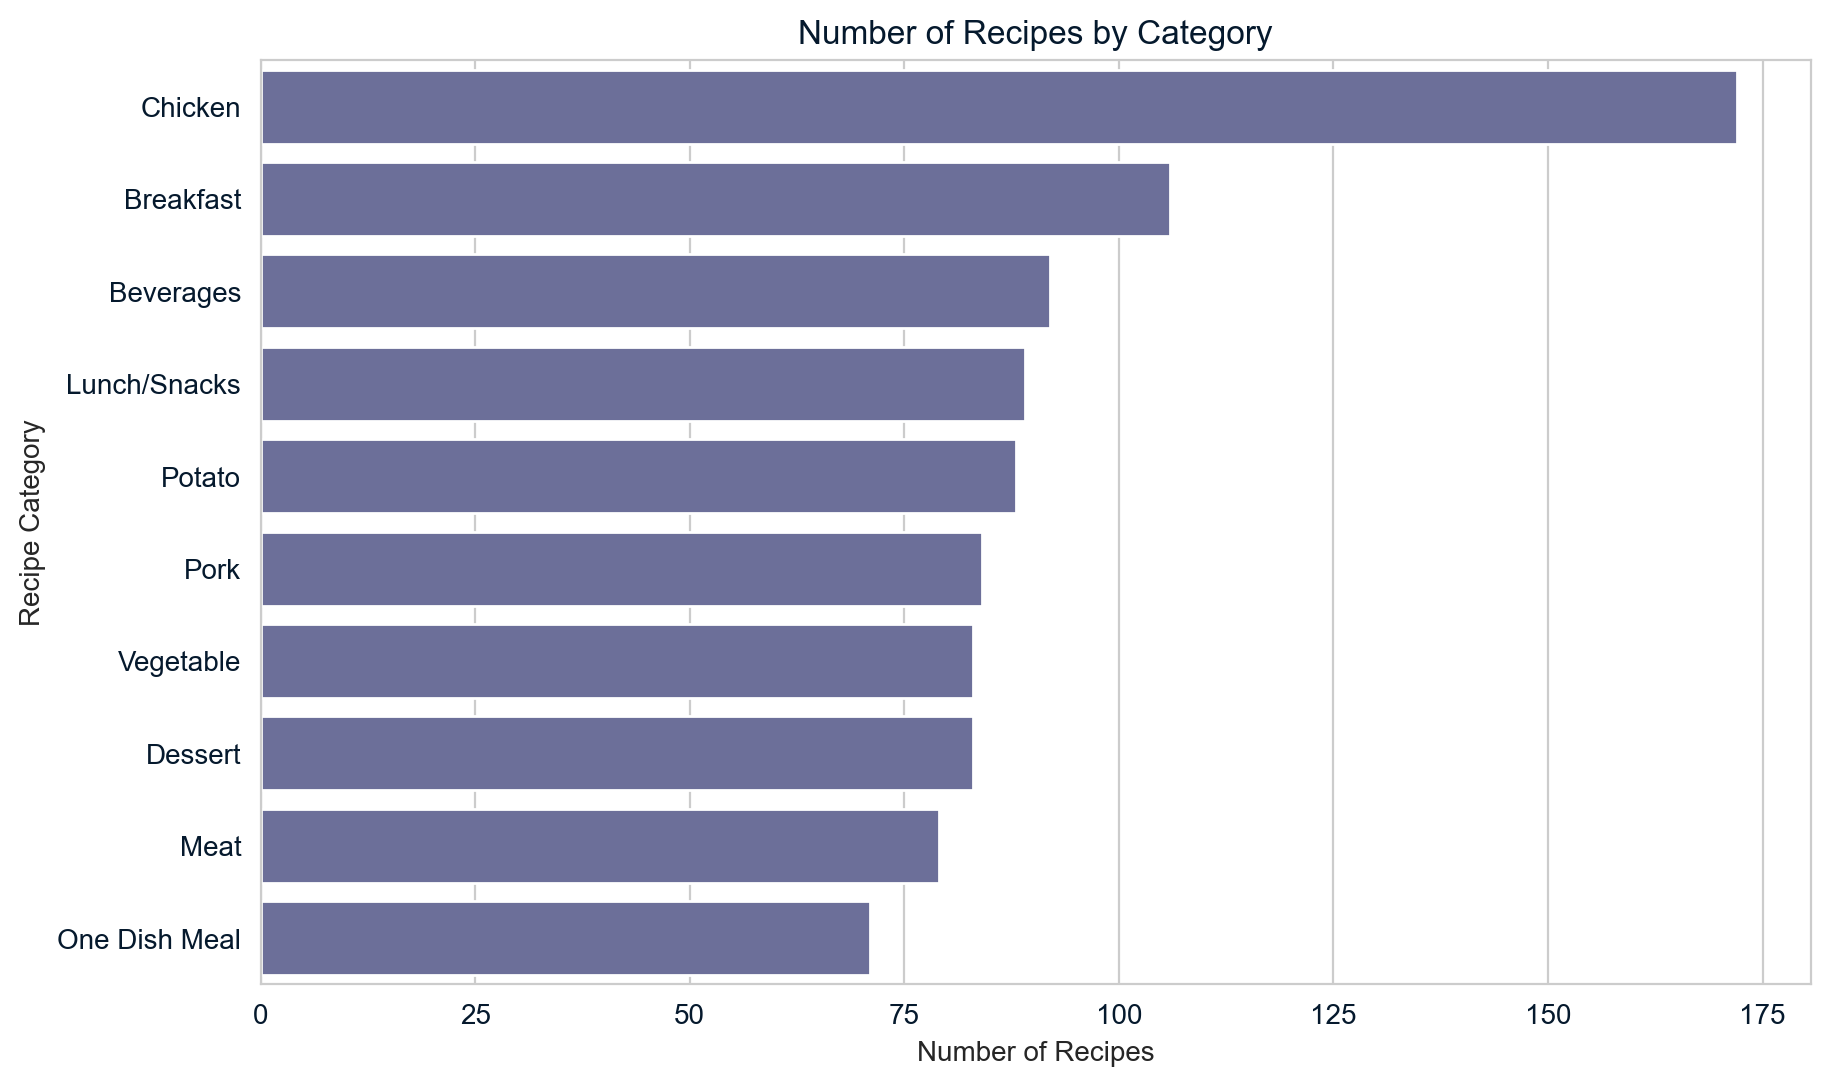

In [6]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clean,
    y='category',
    order=df_clean['category'].value_counts().index
)

plt.title('Number of Recipes by Category')
plt.xlabel('Number of Recipes')
plt.ylabel('Recipe Category')

plt.show()

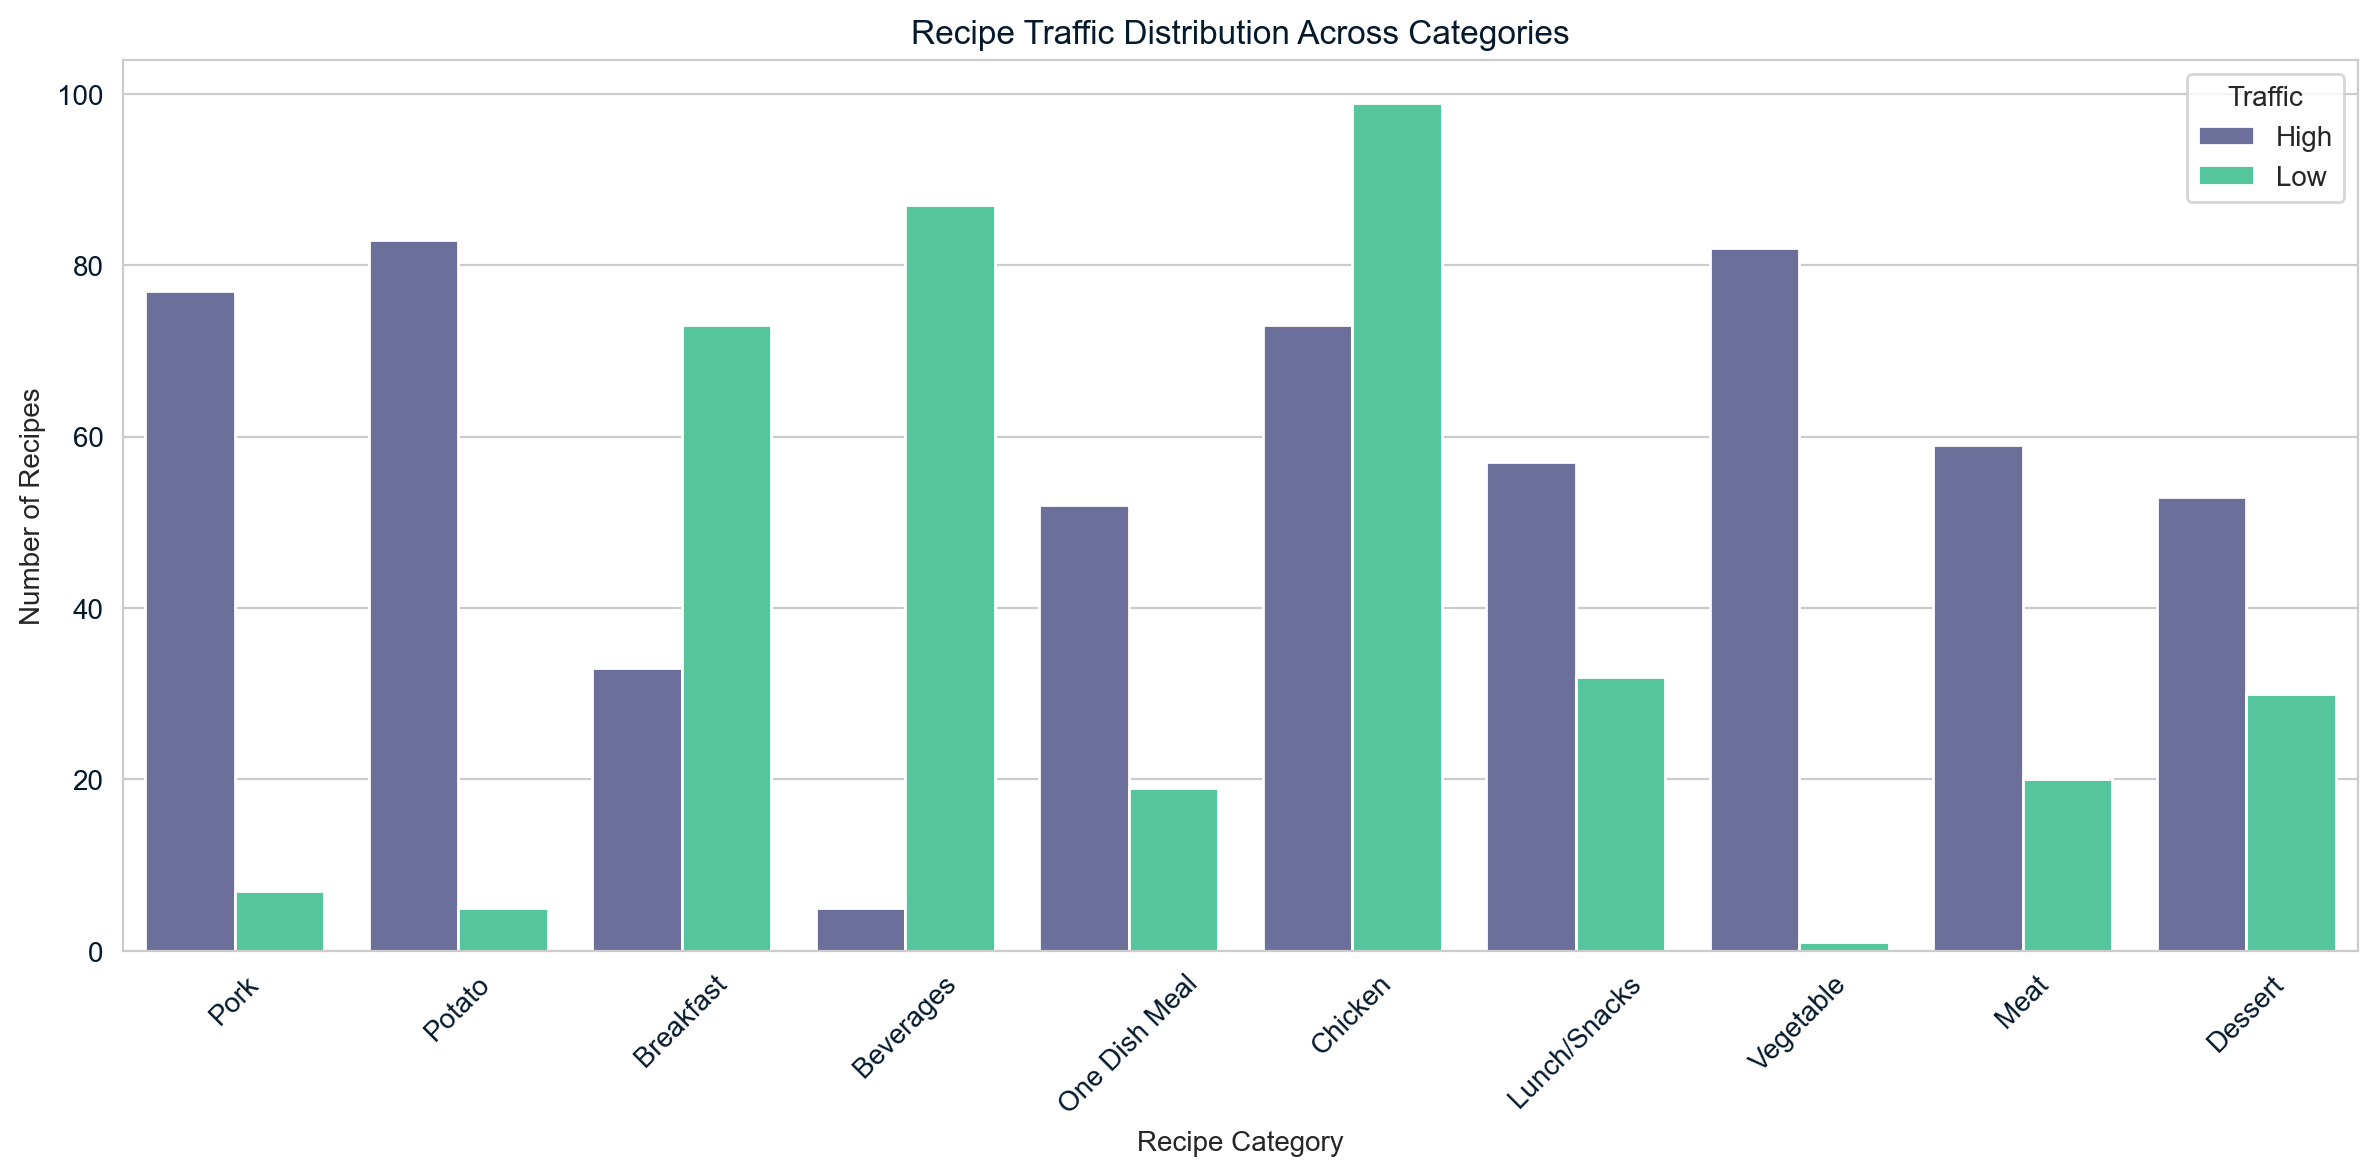

In [7]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    x='category',
    hue='high_traffic'
)

plt.title('Recipe Traffic Distribution Across Categories')
plt.xlabel('Recipe Category')
plt.ylabel('Number of Recipes')

plt.xticks(rotation=45)
plt.legend(title='Traffic')

plt.tight_layout()
plt.show()

high_traffic    High   Low 
category                   
Vegetable      98.80   1.20
Potato         94.32   5.68
Pork           91.67   8.33
Meat           74.68  25.32
One Dish Meal  73.24  26.76
Lunch/Snacks   64.04  35.96
Dessert        63.86  36.14
Chicken        42.44  57.56
Breakfast      31.13  68.87
Beverages       5.43  94.57


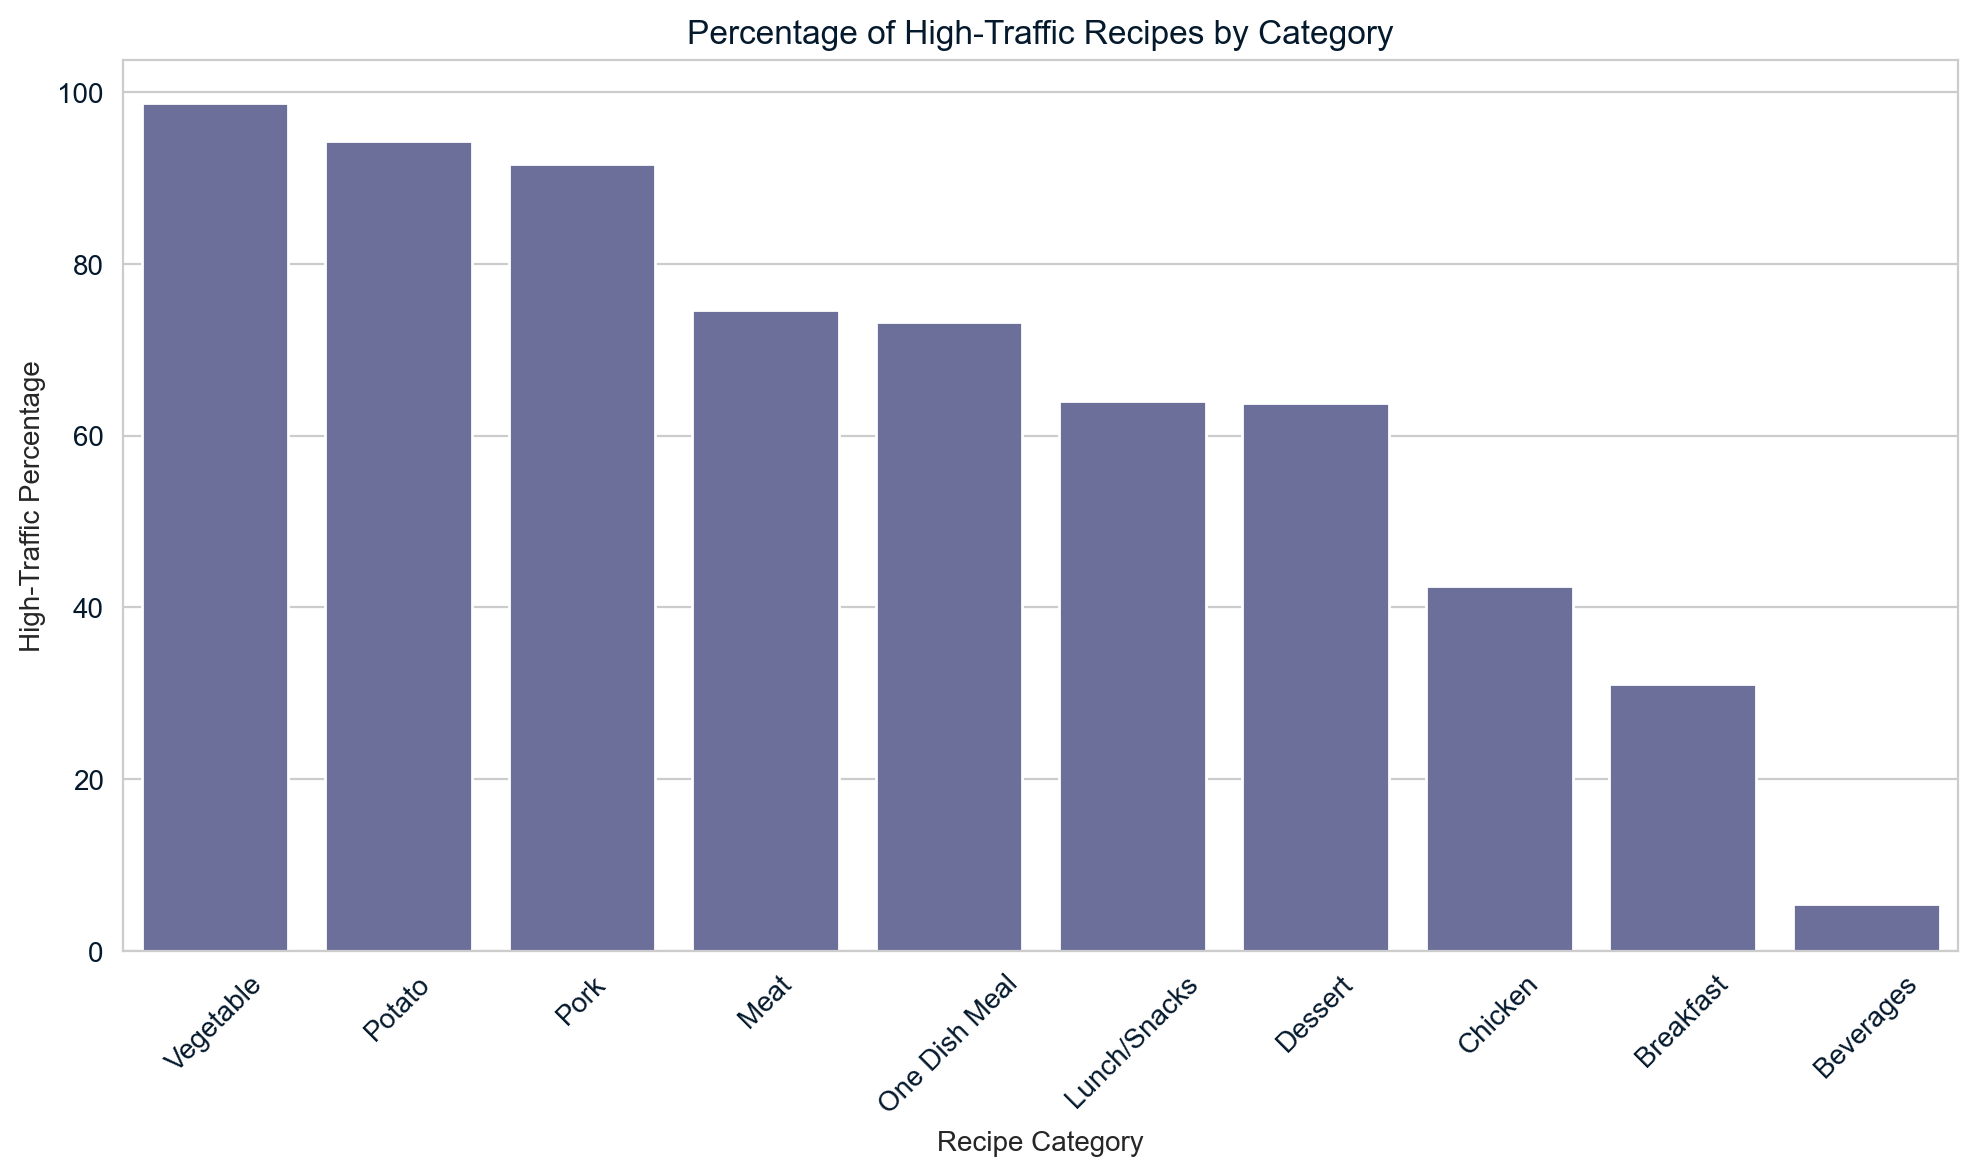

In [8]:
category_traffic = pd.crosstab(
    df_clean['category'],
    df_clean['high_traffic'],
    normalize='index'
) * 100

category_traffic = category_traffic.sort_values(
    by='High',
    ascending=False
)

print(category_traffic.round(2))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_traffic.index,
    y=category_traffic['High']
)

plt.title('Percentage of High-Traffic Recipes by Category')
plt.xlabel('Recipe Category')
plt.ylabel('High-Traffic Percentage')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Category-wise Traffic Analysis

The category-wise analysis shows that recipe category has a strong association with website traffic. Vegetable recipes have the highest high-traffic percentage at 98.80%, followed by Potato at 94.32% and Pork at 91.67%.

On the other hand, Beverages have the lowest high-traffic percentage at 5.43%. Breakfast and Chicken recipes also show relatively lower performance, with high-traffic percentages of 31.13% and 42.44%, respectively.

These findings suggest that recipe category is an important feature for predicting website traffic. The business could consider prioritizing categories with historically higher traffic when selecting recipes for homepage promotion.

In [9]:
print("Numerical Feature Summary:")
print(
    df_clean[
        ['calories', 'carbohydrate', 'sugar', 'protein', 'servings']
    ].describe().round(2)
)

Numerical Feature Summary:
       calories  carbohydrate   sugar  protein  servings
count    895.00        895.00  895.00   895.00    947.00
mean     435.94         35.07    9.05    24.15      3.48
std      453.02         43.95   14.68    36.37      1.73
min        0.14          0.03    0.01     0.00      1.00
25%      110.43          8.38    1.69     3.20      2.00
50%      288.55         21.48    4.55    10.80      4.00
75%      597.65         44.96    9.80    30.20      4.00
max     3633.16        530.42  148.75   363.36      6.00


### Numerical Feature Analysis

The numerical summary indicates considerable variation in the nutritional values of recipes. Calories, carbohydrates, sugar, and protein have means higher than their respective medians, suggesting positively skewed distributions. Some recipes also have unusually high maximum values, which may indicate potential outliers. The average number of servings is approximately 3.48, while the median is 4 servings.

These observations suggest that nutritional features have different scales and distributions. Therefore, appropriate preprocessing, including median imputation and feature scaling, will be used during model development.

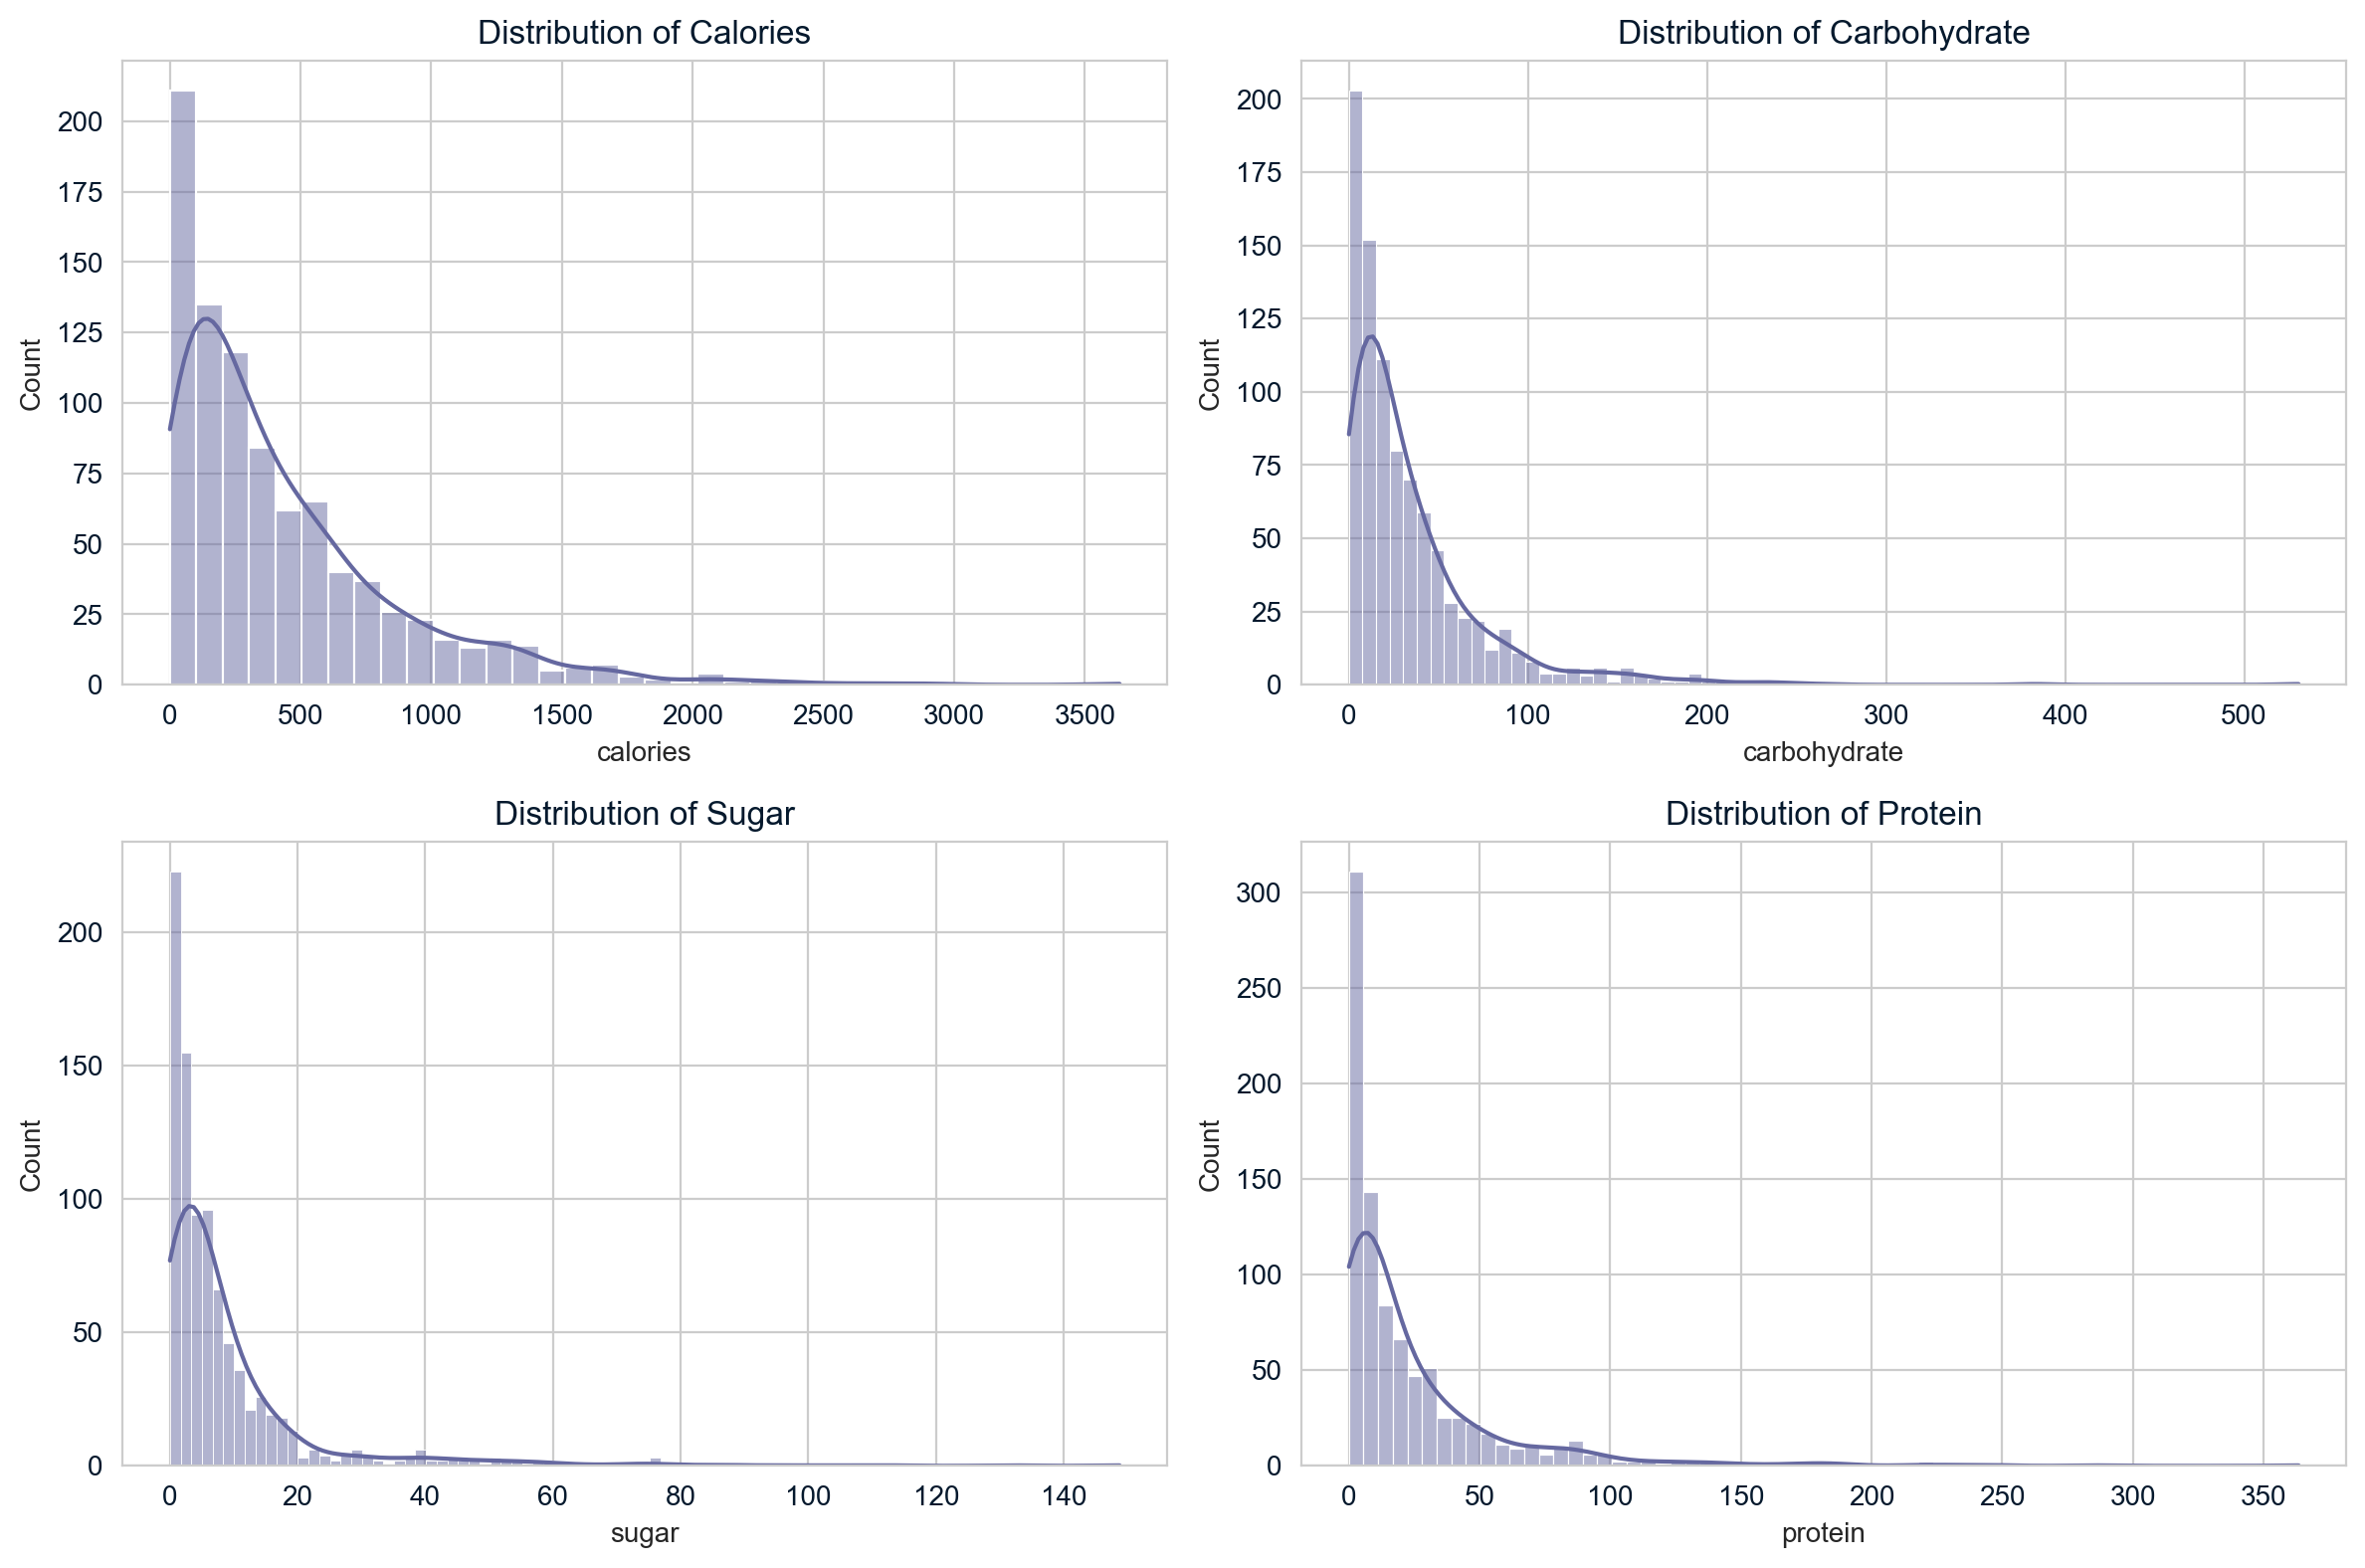

In [12]:
numeric_features = [
    'calories',
    'carbohydrate',
    'sugar',
    'protein'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(numeric_features, axes.flatten()):
    sns.histplot(
        data=df_clean,
        x=col,
        kde=True,
        ax=ax
    )
    ax.set_title(f'Distribution of {col.title()}')

plt.tight_layout()
plt.show() 

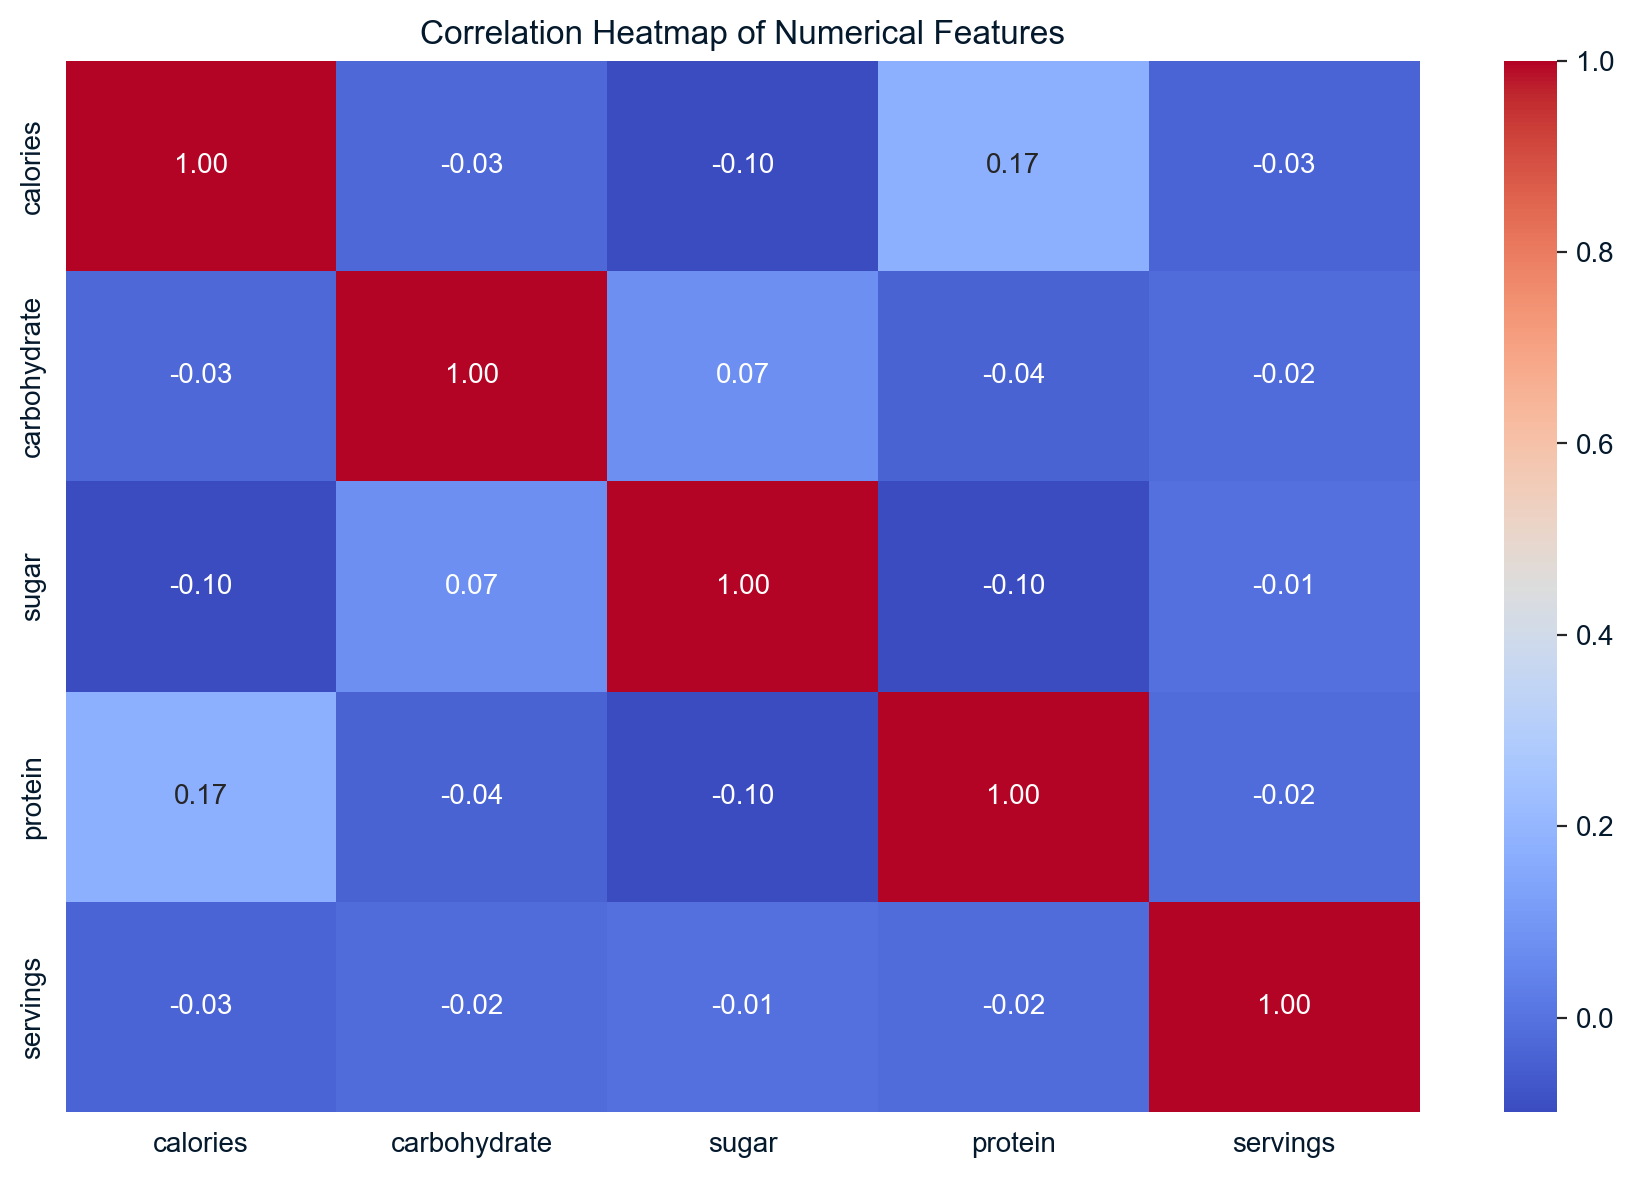

In [13]:
plt.figure(figsize=(9, 6))

correlation = df_clean[
    ['calories', 'carbohydrate', 'sugar', 'protein', 'servings']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

In [14]:
# Define features and target variable

X = df_clean.drop(columns=['recipe', 'high_traffic'])
y = df_clean['high_traffic']

print("Features:")
print(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Features:
   calories  carbohydrate  sugar  protein   category  servings
0       NaN           NaN    NaN      NaN       Pork         6
1     35.48         38.56   0.66     0.92     Potato         4
2    914.28         42.68   3.09     2.88  Breakfast         1
3     97.03         30.56  38.63     0.02  Beverages         4
4     27.05          1.85   0.80     0.53  Beverages         4

Target distribution:
High    574
Low     373
Name: high_traffic, dtype: Int64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (710, 6)
Testing data shape: (237, 6)

Training target distribution:
High    430
Low     280
Name: high_traffic, dtype: Int64

Testing target distribution:
High    144
Low      93
Name: high_traffic, dtype: Int64


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical features
numeric_features = [
    'calories',
    'carbohydrate',
    'sugar',
    'protein',
    'servings'
]

categorical_features = ['category']

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [18]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        class_weight='balanced'
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [20]:
# Predictions using Logistic Regression
y_pred_lr = logistic_model.predict(X_test)

# Predictions using Random Forest
y_pred_rf = rf_model.predict(X_test)

print("Predictions generated successfully.")

print("\nLogistic Regression predictions:")
print(y_pred_lr[:10])

print("\nRandom Forest predictions:")
print(y_pred_rf[:10])

Predictions generated successfully.

Logistic Regression predictions:
['Low' 'High' 'Low' 'High' 'High' 'Low' 'High' 'High' 'Low' 'Low']

Random Forest predictions:
['Low' 'High' 'Low' 'High' 'High' 'Low' 'High' 'High' 'Low' 'Low']


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Logistic Regression metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, pos_label='High')
lr_recall = recall_score(y_test, y_pred_lr, pos_label='High')
lr_f1 = f1_score(y_test, y_pred_lr, pos_label='High')

# Random Forest metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label='High')
rf_recall = recall_score(y_test, y_pred_rf, pos_label='High')
rf_f1 = f1_score(y_test, y_pred_rf, pos_label='High')

# Comparison table
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [lr_accuracy, rf_accuracy],
    'Precision': [lr_precision, rf_precision],
    'Recall': [lr_recall, rf_recall],
    'F1 Score': [lr_f1, rf_f1]
})

print(results.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.751      0.806   0.778     0.792
1        Random Forest     0.709      0.770   0.743     0.756


### Model Evaluation and Comparison

Two classification models, Logistic Regression and Random Forest, were developed and evaluated using accuracy, precision, recall, and F1-score.

Logistic Regression achieved an accuracy of 75.1%, precision of 80.6%, recall of 77.8%, and F1-score of 79.2%.

Random Forest achieved an accuracy of 70.9%, precision of 77.0%, recall of 74.3%, and F1-score of 75.6%.

Based on the comparison, Logistic Regression performed better across all four evaluation metrics. It also achieved the business requirement of at least 80% precision for high-traffic recipes.

Therefore, Logistic Regression is selected as the preferred model for predicting high-traffic recipes.

In [22]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_lr))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_rf))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.81      0.78      0.79       144
         Low       0.67      0.71      0.69        93

    accuracy                           0.75       237
   macro avg       0.74      0.74      0.74       237
weighted avg       0.75      0.75      0.75       237


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.77      0.74      0.76       144
         Low       0.62      0.66      0.64        93

    accuracy                           0.71       237
   macro avg       0.70      0.70      0.70       237
weighted avg       0.71      0.71      0.71       237



### Classification Report Analysis

The classification reports provide a detailed comparison of both models.

Logistic Regression achieved 81% precision, 78% recall, and a 79% F1-score for the High class. Its overall accuracy was approximately 75%.

Random Forest achieved 77% precision, 74% recall, and a 76% F1-score for the High class, with an overall accuracy of approximately 71%.

Logistic Regression performed better in identifying high-traffic recipes and achieved the required business precision target. Therefore, it is considered the preferred model for this classification problem.

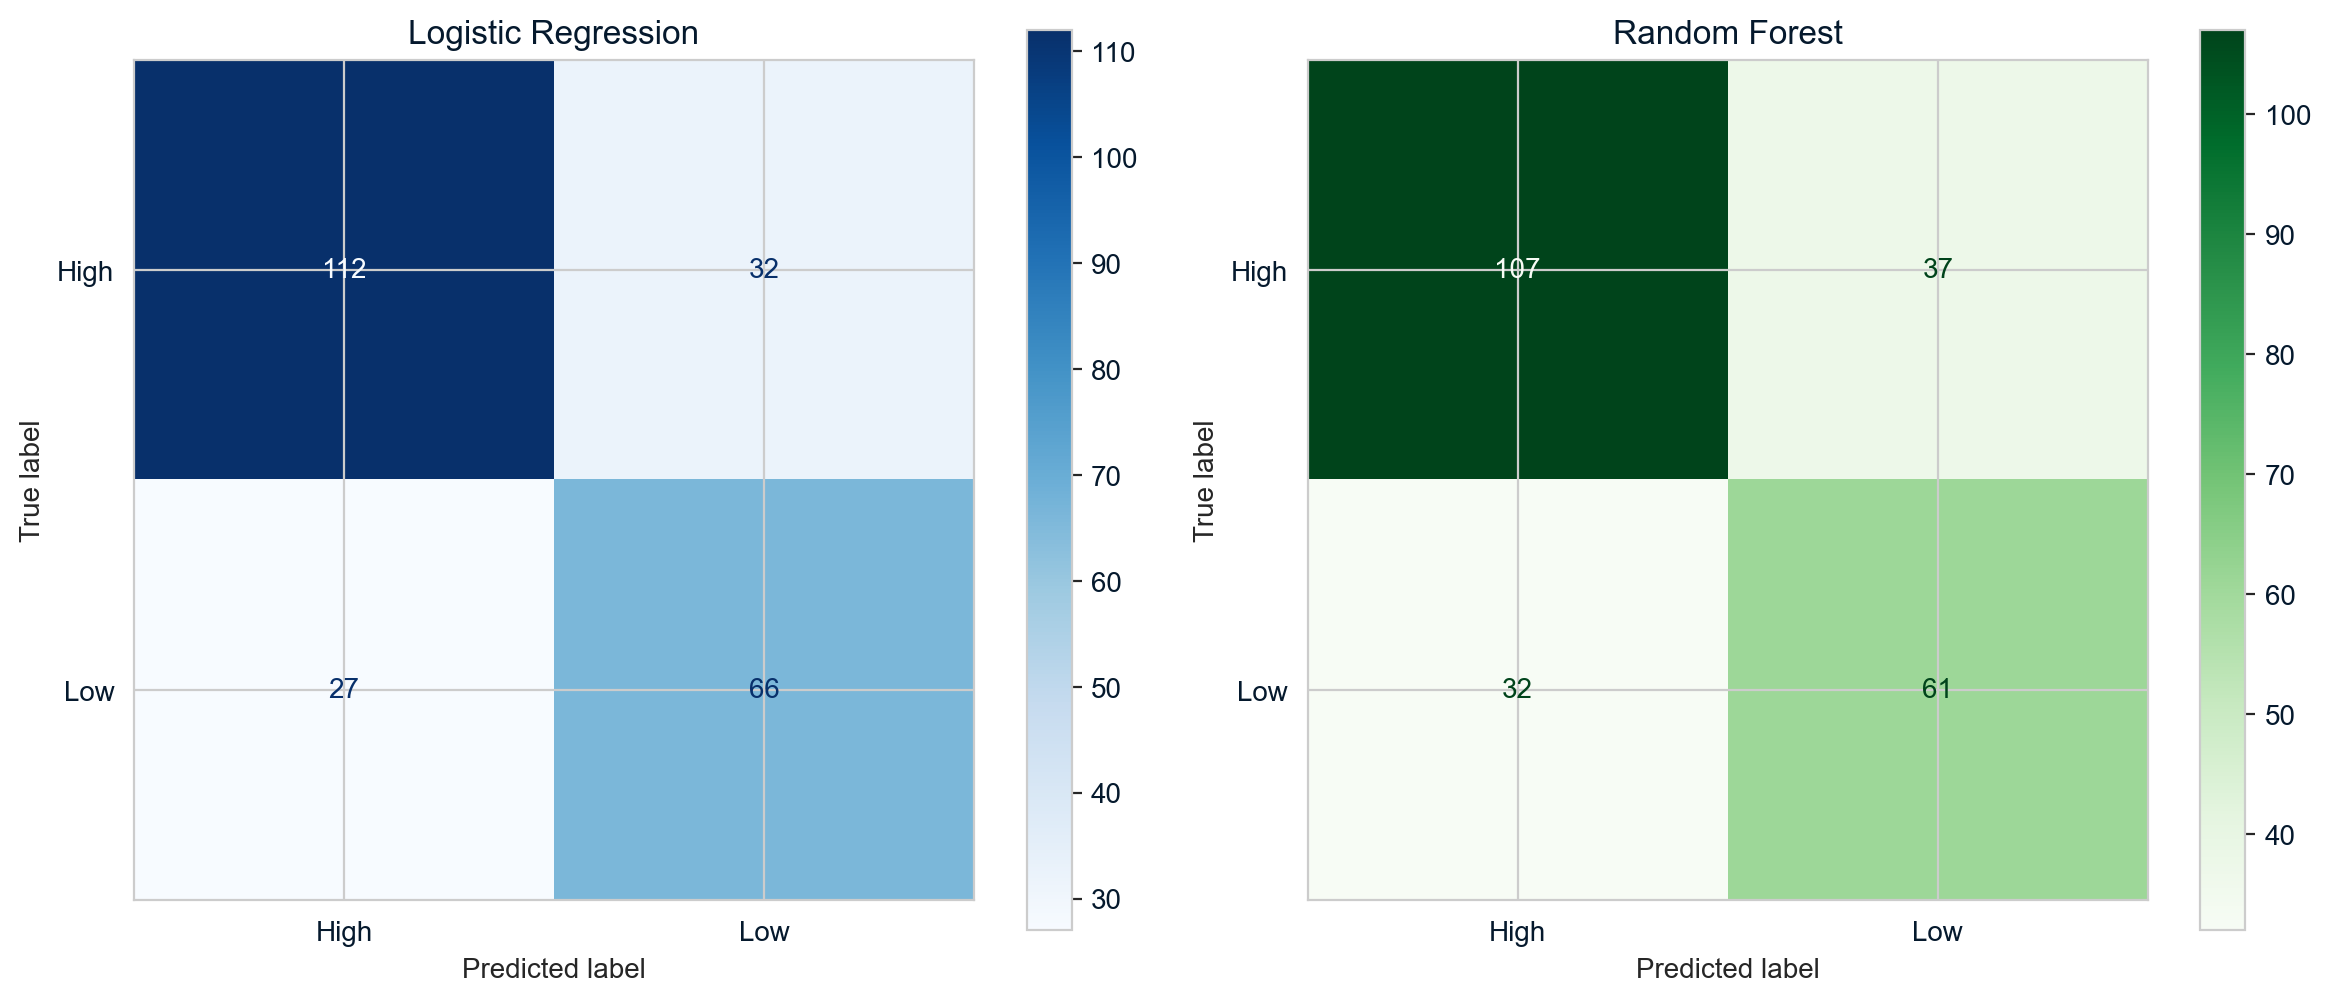

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    ax=axes[0],
    cmap='Blues'
)
axes[0].set_title('Logistic Regression')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    ax=axes[1],
    cmap='Greens'
)
axes[1].set_title('Random Forest')

plt.tight_layout()
plt.show()

In [24]:
# Business metric: Precision for High traffic
business_precision = precision_score(
    y_test,
    y_pred_lr,
    pos_label='High'
)

target_precision = 0.80

print("Business Target:", target_precision)
print("Achieved Precision:", round(business_precision, 3))

if business_precision >= target_precision:
    print("Business target achieved!")
else:
    print("Business target not achieved.")

Business Target: 0.8
Achieved Precision: 0.806
Business target achieved!


### Business Metric Evaluation

The primary business objective was to identify recipes that would generate high website traffic while ensuring that at least 80% of the recipes predicted as high-traffic actually receive high traffic.

Precision for the High class was selected as the primary business metric.

The Logistic Regression model achieved a precision of 80.6%, exceeding the required target of 80%. Therefore, the model successfully meets the business requirement.

The business can use this model to support homepage recipe selection and prioritize recipes that are more likely to attract website traffic.

In [26]:
# Select the best-performing model
best_model = logistic_model

print("Selected Model: Logistic Regression")
print("Accuracy:", round(lr_accuracy, 3))
print("Precision:", round(lr_precision, 3))
print("Recall:", round(lr_recall, 3))
print("F1 Score:", round(lr_f1, 3))

Selected Model: Logistic Regression
Accuracy: 0.751
Precision: 0.806
Recall: 0.778
F1 Score: 0.792


In [27]:
print("FINAL PROJECT CONCLUSION")
print("-------------------------")
print("Best Model: Logistic Regression")
print("Accuracy:", round(lr_accuracy * 100, 2), "%")
print("High Traffic Precision:", round(lr_precision * 100, 2), "%")
print("High Traffic Recall:", round(lr_recall * 100, 2), "%")
print("F1 Score:", round(lr_f1 * 100, 2), "%")

print("\nBusiness Target: 80%")
print("Achieved:", round(lr_precision * 100, 2), "%")

print("\nConclusion: Business target achieved!")

FINAL PROJECT CONCLUSION
-------------------------
Best Model: Logistic Regression
Accuracy: 75.11 %
High Traffic Precision: 80.58 %
High Traffic Recall: 77.78 %
F1 Score: 79.15 %

Business Target: 80%
Achieved: 80.58 %

Conclusion: Business target achieved!


### Conclusion and Business Recommendations

The objective of this project was to predict whether a recipe would generate high website traffic.

After performing data cleaning, exploratory data analysis, and developing two classification models, Logistic Regression and Random Forest, Logistic Regression was selected as the final model.

The selected model achieved 75.11% accuracy, 80.58% precision, 77.78% recall, and 79.15% F1-score.

The model successfully exceeded the business requirement of 80% precision for high-traffic recipes.

Based on the findings, the business should prioritize recipe categories that historically generate higher traffic, particularly Vegetable, Potato, and Pork. The selected model can assist the product team in making more informed decisions when choosing recipes for homepage promotion.

Overall, the project demonstrates how machine learning can support data-driven recipe selection and improve website traffic planning.

## Project Notes

This notebook documents the analysis and modelling workflow for the Recipe Site Traffic project.
Run the notebook from the `notebooks/` directory so the relative dataset path resolves correctly.
